# TF Site x Kinase Module Heatmap

Subsetted down to just the two heatmaps: the full version (all modules) and the final version (modules 4, 9, 10, 12 excluded).

## 0. Imports & paths

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
import kinase_library as kl

# significant/dynamic phosphosites, with geneSymbol, VMsiteFlanks, AND a
# per-site is_tf flag all included directly -- replaces sig_sites_f,
# phospho_data_f, and all 3 motif-enrichment TF files entirely. TF
# identity now comes purely from this file's own is_tf column, tied
# directly to the phosphoproteomics data, not any motif-based TF list.
tf_flag_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_ids_and_flanks.csv"

module_assignments_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/out_files/kinase_module_assignments.csv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap"
fig_out = f"{out_dir}/figures"
os.makedirs(fig_out, exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

KL_THRESH = 15  # must match kl_thresh used for ser_thr in the MEA generation script

## 1. Load kinase modules and dynamic Ser/Thr TF sites

In [3]:
import re

module_df = pd.read_csv(module_assignments_f)

# already the significant/dynamic phosphosite set -- geneSymbol,
# VMsiteFlanks, and is_tf all provided directly, no id-splitting or
# cross-referencing against separate files needed
dyn_sites = pd.read_csv(tf_flag_f)


def split_site_tokens(combined_token):
    """Split a combined multi-site token like 'S127sT132t' into
    individual site tokens ['S127s', 'T132t']. A single-site token like
    'S136s' returns just ['S136s']."""
    return re.findall(r'[A-Z]\d+[a-z]', combined_token)


# Expand each row into ONE ROW PER INDIVIDUAL PHOSPHOSITE. A row like
# id="Q62431_S127sT132t_..." with VMsiteFlanks="flankA|flankB" represents
# TWO separate physical sites (S127, T132) collapsed into one row --
# split the combined site token and the pipe-joined flanks into matching
# individual pairs, so S127 and T132 become fully independent site_label
# rows from here on, rather than being re-merged via min() at the
# scoring step later.
expanded_rows = []
n_mismatch = 0
for _, row in dyn_sites.iterrows():
    combined_site_token = row["id"].split("_")[1]
    site_tokens = split_site_tokens(combined_site_token)
    flanks = row["VMsiteFlanks"].split("|")

    if len(site_tokens) != len(flanks):
        n_mismatch += 1
        continue

    for site_token, flank in zip(site_tokens, flanks):
        expanded_rows.append({
            "id": row["id"], "geneSymbol": row["geneSymbol"],
            "site_token": site_token, "VMsiteFlanks": flank, "is_tf": row["is_tf"],
        })

if n_mismatch:
    print(f"WARNING: {n_mismatch} rows had a site-token/flank count mismatch, skipped")

dyn_sites_expanded = pd.DataFrame(expanded_rows)
print(f"Expanded {len(dyn_sites)} rows -> {len(dyn_sites_expanded)} individual-site rows")

dyn_tf_sites = dyn_sites_expanded.loc[dyn_sites_expanded["is_tf"] == True].copy().reset_index(drop=True)
dyn_tf_sites["site_label"] = dyn_tf_sites["geneSymbol"] + "_" + dyn_tf_sites["site_token"]
# same (gene, site_token) can arise from multiple original phosphopeptide
# rows (e.g. a residue reported standalone AND as part of a multi-site
# peptide) -- keep only the first occurrence rather than treating them
# as separate _dup-suffixed entities
n_before_dedup = len(dyn_tf_sites)
dyn_tf_sites = dyn_tf_sites.drop_duplicates(subset="site_label", keep="first").reset_index(drop=True)
print(f"TF sites: {n_before_dedup} -> {len(dyn_tf_sites)} after keeping only the first occurrence of each duplicated site_label")

def get_site_type(seq):
    if 'y' in seq:
        return 'tyrosine'
    elif 's' in seq or 't' in seq:
        return 'ser_thr'
    return None

# each row now has exactly ONE flank already -- no more pipe-splitting needed
dyn_tf_sites["kin_type"] = dyn_tf_sites["VMsiteFlanks"].apply(get_site_type)
dyn_tf_sites_serthr = dyn_tf_sites.loc[dyn_tf_sites.kin_type == "ser_thr"].copy().reset_index(drop=True)

print(f"Module-labeled kinases: {len(module_df)}  |  "
      f"Dynamic Ser/Thr TF sites: {len(dyn_tf_sites_serthr)} "
      f"(dropped {len(dyn_tf_sites) - len(dyn_tf_sites_serthr)} tyrosine/unclassified)")

Expanded 1220 rows -> 1410 individual-site rows
TF sites: 125 -> 120 after keeping only the first occurrence of each duplicated site_label
Module-labeled kinases: 83  |  Dynamic Ser/Thr TF sites: 115 (dropped 5 tyrosine/unclassified)


## 2. Score each TF site against the Ser/Thr kinase panel (percentile rank)

In [4]:
# each row already has exactly one flank (sites were expanded/split in
# the previous cell) -- no more pipe-splitting/explode needed here
flank_df = (
    dyn_tf_sites_serthr[['id', 'site_label', 'VMsiteFlanks']]
    .rename(columns={'VMsiteFlanks': 'sequence'})
    .dropna(subset=['sequence'])
    .assign(sequence=lambda df: df.sequence.str.strip())
    .reset_index(drop=True)
)

pps_data = kl.PhosphoProteomics(flank_df, seq_col='sequence')
pps_data.percentile(kin_type='ser_thr', values_only=True)
percentile_ranks = pps_data.ser_thr_percentile_ranks.copy()
percentile_ranks['id'] = flank_df['id'].values
percentile_ranks['site_label'] = flank_df['site_label'].values

long = percentile_ranks.melt(id_vars=['id', 'site_label'], var_name='kinase', value_name='percentile_rank')
long['kinase'] = long['kinase'].str.upper()

# safety net only now (sites are already individually expanded) -- collapses
# any remaining incidental duplicate site_label+kinase rows to the best rank
site_kinase_rank = (
    long.groupby(['site_label', 'kinase'])['percentile_rank']
    .min()
    .reset_index()
)
print(f"Scored {site_kinase_rank.site_label.nunique()} sites x {site_kinase_rank.kinase.nunique()} kinases")

Scoring 115 ser_thr substrates
Calculating percentile for 115 ser_thr substrates


Percentile scoring: 100%|██████████| 311/311 [00:00<00:00, 18168.29it/s]


Scored 115 sites x 311 kinases


## 3. Top-15 predicted kinases per site (input to the module enrichment test)

In [5]:
top15_per_site = (
    site_kinase_rank[site_kinase_rank["percentile_rank"] <= KL_THRESH]
    .sort_values(["site_label", "percentile_rank"])
)
print(f"Top-15 kinase assignments: {top15_per_site.shape[0]} rows")

Top-15 kinase assignments: 1734 rows


## 4. Module enrichment per TF site (Fisher's exact) -- produces `enrich_df`

In [6]:
module_kinase_set = set(module_df["kinase"])
kinase_to_module  = dict(zip(module_df["kinase"], module_df["module"]))
module_ids        = sorted(module_df["module"].unique())
module_sizes      = module_df["module"].value_counts()
total_kinases     = len(module_kinase_set)

candidates = top15_per_site[top15_per_site["kinase"].isin(module_kinase_set)].copy()
candidates["module"] = candidates["kinase"].map(kinase_to_module)

results = []
for site, site_cands in candidates.groupby("site_label"):
    n_cand = len(site_cands)
    cand_modules = site_cands["module"].value_counts()
    for m in module_ids:
        a = cand_modules.get(m, 0)
        b = n_cand - a
        c = module_sizes.get(m, 0) - a
        d = total_kinases - n_cand - c
        odds_ratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
        results.append({"site_label": site, "module": m, "n_candidates_in_module": a,
                         "n_candidates_total": n_cand, "module_size": module_sizes.get(m, 0),
                         "odds_ratio": odds_ratio, "p_value": p})

enrich_df = pd.DataFrame(results)
enrich_df["neg_log10_p"] = -np.log10(enrich_df["p_value"].clip(lower=1e-300))
print(f"Sites with >=1 module-labeled candidate kinase: {candidates.site_label.nunique()} / "
      f"{top15_per_site.site_label.nunique()}")

# save the enrichment table itself -- kinase_tf_group_panel.ipynb reads a
# saved module-vs-TF summary CSV; this is that file, produced by this
# notebook directly rather than an unseen separate script
summary_out = f"{out_dir}/out_files/tf_module_overlap_summary.csv"
enrich_df.to_csv(summary_out, index=False)
print(f"Saved: {summary_out}")

Sites with >=1 module-labeled candidate kinase: 111 / 115
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/out_files/tf_module_overlap_summary.csv


## 5. FULL heatmap -- TF site x module (-log10 p-value), all modules

SVG is rasterized (heatmap body only) so the file stays small -- a true-vector heatmap would draw one path per cell.

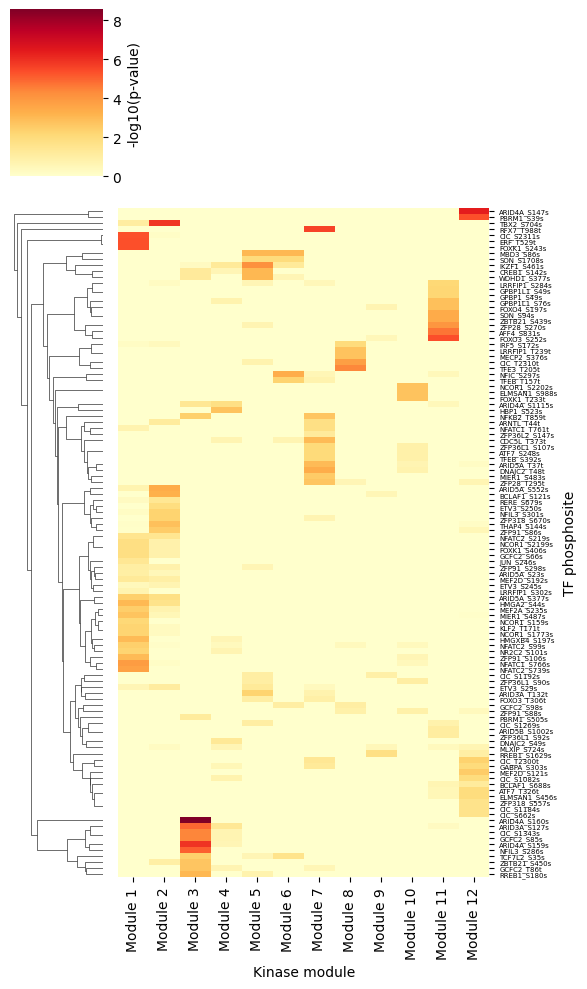

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_full.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_full.svg


In [7]:
pivot = enrich_df.pivot(index="site_label", columns="module", values="neg_log10_p")
pivot.columns = [f"Module {m}" for m in pivot.columns]

g = sns.clustermap(
    pivot.fillna(0), cmap="YlOrRd", col_cluster=False,
    figsize=(6, 10),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "-log10(p-value)"}
)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=5)
g.ax_heatmap.set_xlabel("Kinase module")
g.ax_heatmap.set_ylabel("TF phosphosite")

for collection in g.ax_heatmap.collections:
    collection.set_rasterized(True)

plt.tight_layout()

png_out = f"{fig_out}/tf_site_module_enrichment_heatmap_full.png"
svg_out = f"{fig_out}/tf_site_module_enrichment_heatmap_full.svg"
g.savefig(png_out, dpi=300, bbox_inches="tight")
g.savefig(svg_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out}")
print(f"Saved: {svg_out}")

## 6. FINAL heatmap -- modules 4, 9, 10, 12 excluded, p<0.1 cutoff applied

Drops columns (modules) first -- clustermap re-clusters rows fresh on
the reduced set of columns, since removing modules changes each site's
enrichment profile and therefore how sites should group together. Then
drops rows (TF sites): any site whose best remaining module enrichment
doesn't clear p<0.1 gets excluded from this final heatmap entirely.

Modules: 12 -> 7 after excluding [4, 9, 10, 12] and merging 5+6
TF sites: 111 -> 90 after requiring p<0.1 (neg_log10_p>1.000) in at least one displayed module
p<0.1: 90 sites enriched in >=1 module | 79 in exactly 1 (88%) | 11 in >1 (12%)
p<0.05: 77 sites enriched in >=1 module | 72 in exactly 1 (94%) | 5 in >1 (6%)

Modules passed per site (p<0.1):
1    79
2    11

Per-module specificity:
    module  n_sites_enriched  n_module_specific
  Module 1                24                 20
  Module 2                14                  8
  Module 3                15                 11
Module 5_6                15                 10
  Module 7                15                 13
  Module 8                 6                  5
 Module 11                12                 12
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/out_files/tf_site_module_specificity.csv


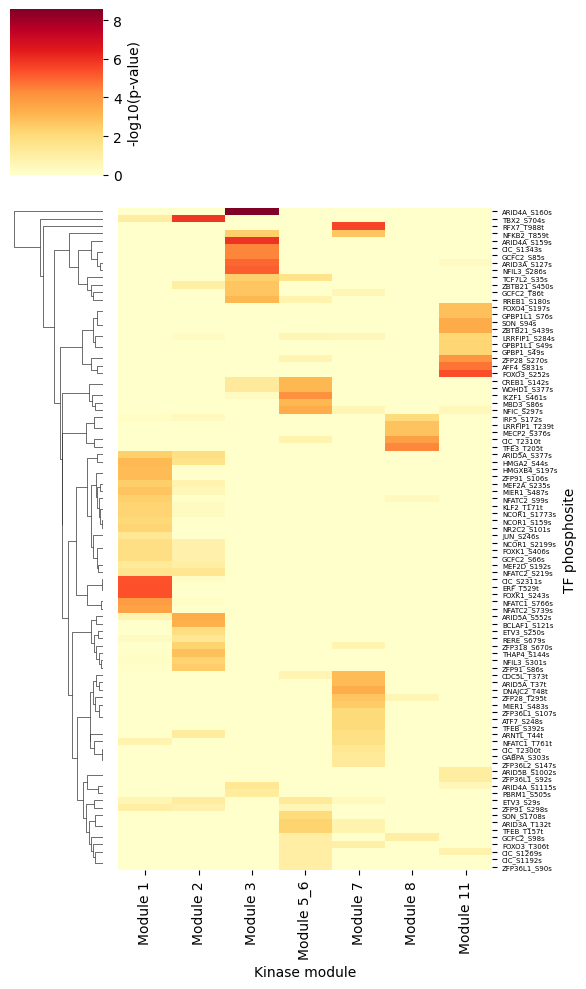

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_final.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_final.svg


In [8]:
EXCLUDED_MODULES = [4, 9, 10, 12]

# Merge modules 5 and 6 into one combined "Module 5_6" column, same
# meta-module grouping as the fig3a kinase heatmap. Combined via
# max(neg_log10_p) across the two -- i.e. whichever of the two module
# tests gave the stronger (more significant) signal for that site --
# rather than summing/averaging, since these are already -log10(p)
# values from two separate Fisher's exact tests, and taking the
# stronger signal is the defensible way to combine two significance
# tests into one displayed value.
MODULE_MERGE = {5: "5_6", 6: "5_6"}

def display_module(m):
    return MODULE_MERGE.get(m, m)

modules_present_raw = [m for m in module_ids if m not in EXCLUDED_MODULES]
display_order = sorted(
    set(display_module(m) for m in modules_present_raw),
    key=lambda d: min(m for m in modules_present_raw if display_module(m) == d),
)

pivot_final = pd.DataFrame(index=pivot.index)
for d in display_order:
    raw_modules = [m for m in modules_present_raw if display_module(m) == d]
    cols = [f"Module {m}" for m in raw_modules if f"Module {m}" in pivot.columns]
    pivot_final[f"Module {d}"] = pivot[cols].max(axis=1)

print(f"Modules: {pivot.shape[1]} -> {pivot_final.shape[1]} after excluding {EXCLUDED_MODULES} and merging 5+6")

# drop TF sites (rows) that don't clear p<0.1 in AT LEAST ONE of the
# modules actually displayed here (after excluding modules 4/9/10/12 and
# merging 5+6) -- a site whose best remaining module enrichment is
# non-significant even at this permissive threshold isn't worth showing
# on the final heatmap
PVAL_CUTOFF = 0.1
neg_log10_p_cutoff = -np.log10(PVAL_CUTOFF)

n_sites_before = len(pivot_final)
pivot_final = pivot_final.loc[pivot_final.max(axis=1) > neg_log10_p_cutoff]
print(f"TF sites: {n_sites_before} -> {len(pivot_final)} after requiring p<{PVAL_CUTOFF} "
      f"(neg_log10_p>{neg_log10_p_cutoff:.3f}) in at least one displayed module")

# =============================================================================
# MODULE SPECIFICITY: how many displayed modules does each TF site pass?
# Sites are individual phosphosites (site_label), not proteins, so e.g.
# TFEB_T157t and TFEB_S392s are counted separately.
# =============================================================================
def module_specificity(pivot_df, p_cutoff):
    thresh = -np.log10(p_cutoff)
    passed = pivot_df.fillna(0) > thresh      # sites x modules, bool
    n_mod = passed.sum(axis=1)                # modules passed per site
    return passed, n_mod

# report at the figure's cutoff (p<0.1) and a stricter one (p<0.05)
for cutoff in [0.1, 0.05]:
    _passed, _n_mod = module_specificity(pivot_final, cutoff)
    n_any = int((_n_mod >= 1).sum())
    n_single = int((_n_mod == 1).sum())
    n_multi = int((_n_mod > 1).sum())
    print(f"p<{cutoff}: {n_any} sites enriched in >=1 module | "
          f"{n_single} in exactly 1 ({100 * n_single / max(n_any, 1):.0f}%) | "
          f"{n_multi} in >1 ({100 * n_multi / max(n_any, 1):.0f}%)")

# main summary at the figure's cutoff
passed, n_mod = module_specificity(pivot_final, PVAL_CUTOFF)

print("\nModules passed per site (p<%s):" % PVAL_CUTOFF)
print(n_mod.value_counts().sort_index().to_string())

# per-module table: sites enriched, and how many of those are module-specific
spec_rows = []
for col in pivot_final.columns:
    in_mod_mask = passed[col].values
    in_mod = passed.index[in_mod_mask]
    specific_mask = (n_mod.loc[in_mod] == 1).values
    spec_rows.append({
        "module": col,
        "n_sites_enriched": len(in_mod),
        "n_module_specific": int(specific_mask.sum()),
        "module_specific_sites": ", ".join(sorted(in_mod[specific_mask])),
    })
specificity_df = pd.DataFrame(spec_rows)

print("\nPer-module specificity:")
print(specificity_df.drop(columns="module_specific_sites").to_string(index=False))

specificity_df.to_csv(f"{out_dir}/out_files/tf_site_module_specificity.csv", index=False)
print(f"Saved: {out_dir}/out_files/tf_site_module_specificity.csv")
# =============================================================================

g_final = sns.clustermap(
    pivot_final.fillna(0), cmap="YlOrRd", col_cluster=False,
    figsize=(6, 10),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "-log10(p-value)"}
)
g_final.ax_heatmap.set_yticklabels(g_final.ax_heatmap.get_yticklabels(), fontsize=5)
g_final.ax_heatmap.set_xlabel("Kinase module")
g_final.ax_heatmap.set_ylabel("TF phosphosite")

for collection in g_final.ax_heatmap.collections:
    collection.set_rasterized(True)

plt.tight_layout()

png_out_final = f"{fig_out}/tf_site_module_enrichment_heatmap_final.png"
svg_out_final = f"{fig_out}/tf_site_module_enrichment_heatmap_final.svg"
g_final.savefig(png_out_final, dpi=300, bbox_inches="tight")
g_final.savefig(svg_out_final, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out_final}")
print(f"Saved: {svg_out_final}")

Modules: 12 -> 7 after excluding [4, 9, 10, 12] and merging 5+6
TF sites: 111 -> 90 after requiring p<0.1 (neg_log10_p>1.000) in at least one displayed module


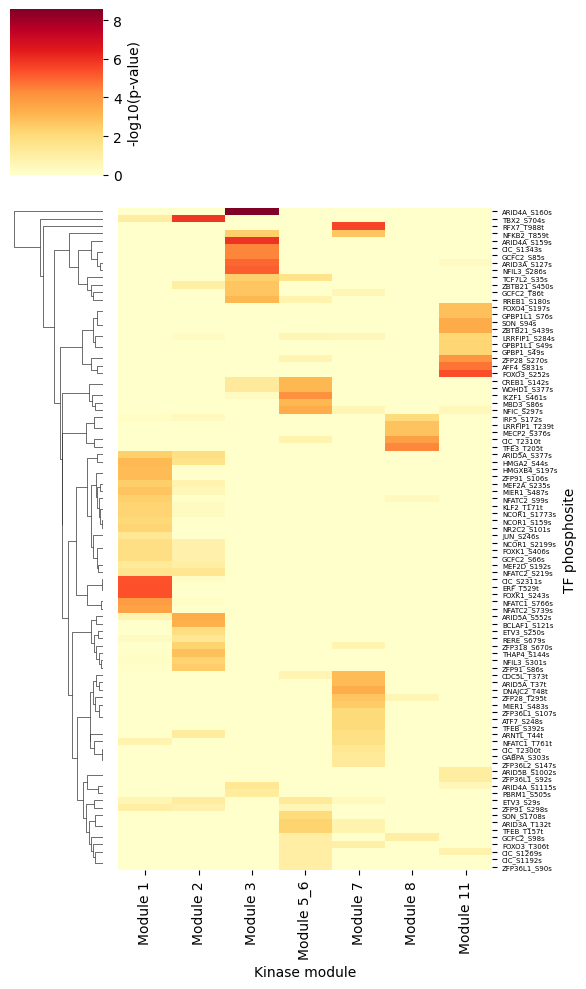

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_final.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_final.svg


In [9]:
EXCLUDED_MODULES = [4, 9, 10, 12]

# Merge modules 5 and 6 into one combined "Module 5_6" column, same
# meta-module grouping as the fig3a kinase heatmap. Combined via
# max(neg_log10_p) across the two -- i.e. whichever of the two module
# tests gave the stronger (more significant) signal for that site --
# rather than summing/averaging, since these are already -log10(p)
# values from two separate Fisher's exact tests, and taking the
# stronger signal is the defensible way to combine two significance
# tests into one displayed value.
MODULE_MERGE = {5: "5_6", 6: "5_6"}

def display_module(m):
    return MODULE_MERGE.get(m, m)

modules_present_raw = [m for m in module_ids if m not in EXCLUDED_MODULES]
display_order = sorted(
    set(display_module(m) for m in modules_present_raw),
    key=lambda d: min(m for m in modules_present_raw if display_module(m) == d),
)

pivot_final = pd.DataFrame(index=pivot.index)
for d in display_order:
    raw_modules = [m for m in modules_present_raw if display_module(m) == d]
    cols = [f"Module {m}" for m in raw_modules if f"Module {m}" in pivot.columns]
    pivot_final[f"Module {d}"] = pivot[cols].max(axis=1)

print(f"Modules: {pivot.shape[1]} -> {pivot_final.shape[1]} after excluding {EXCLUDED_MODULES} and merging 5+6")

# drop TF sites (rows) that don't clear p<0.1 in AT LEAST ONE of the
# modules actually displayed here (after excluding modules 4/9/10/12 and
# merging 5+6) -- a site whose best remaining module enrichment is
# non-significant even at this permissive threshold isn't worth showing
# on the final heatmap
PVAL_CUTOFF = 0.1
neg_log10_p_cutoff = -np.log10(PVAL_CUTOFF)

n_sites_before = len(pivot_final)
pivot_final = pivot_final.loc[pivot_final.max(axis=1) > neg_log10_p_cutoff]
print(f"TF sites: {n_sites_before} -> {len(pivot_final)} after requiring p<{PVAL_CUTOFF} "
      f"(neg_log10_p>{neg_log10_p_cutoff:.3f}) in at least one displayed module")

g_final = sns.clustermap(
    pivot_final.fillna(0), cmap="YlOrRd", col_cluster=False,
    figsize=(6, 10),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "-log10(p-value)"}
)
g_final.ax_heatmap.set_yticklabels(g_final.ax_heatmap.get_yticklabels(), fontsize=5)
g_final.ax_heatmap.set_xlabel("Kinase module")
g_final.ax_heatmap.set_ylabel("TF phosphosite")

for collection in g_final.ax_heatmap.collections:
    collection.set_rasterized(True)

plt.tight_layout()

png_out_final = f"{fig_out}/tf_site_module_enrichment_heatmap_final.png"
svg_out_final = f"{fig_out}/tf_site_module_enrichment_heatmap_final.svg"
g_final.savefig(png_out_final, dpi=300, bbox_inches="tight")
g_final.savefig(svg_out_final, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out_final}")
print(f"Saved: {svg_out_final}")

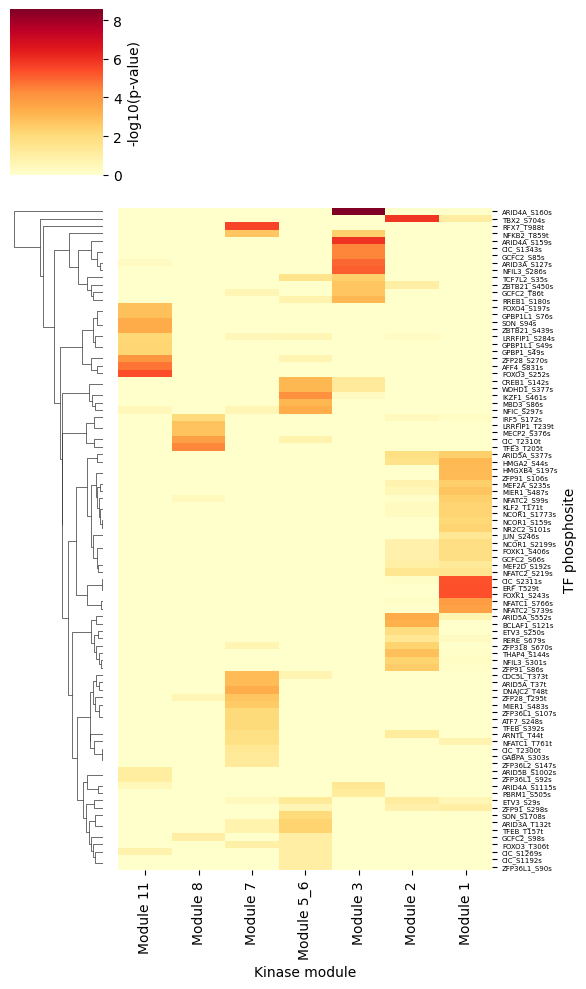

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_final_reversed.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/TFsite_module_heatmap/figures/tf_site_module_enrichment_heatmap_final_reversed.svg


In [10]:
pivot_final_reversed = pivot_final[pivot_final.columns[::-1]]

g_final_rev = sns.clustermap(
    pivot_final_reversed.fillna(0), cmap="YlOrRd", col_cluster=False,
    figsize=(6, 10),
    yticklabels=True, xticklabels=True,
    cbar_kws={"label": "-log10(p-value)"}
)
g_final_rev.ax_heatmap.set_yticklabels(g_final_rev.ax_heatmap.get_yticklabels(), fontsize=5)
g_final_rev.ax_heatmap.set_xlabel("Kinase module")
g_final_rev.ax_heatmap.set_ylabel("TF phosphosite")

for collection in g_final_rev.ax_heatmap.collections:
    collection.set_rasterized(True)

plt.tight_layout()

png_out_final_rev = f"{fig_out}/tf_site_module_enrichment_heatmap_final_reversed.png"
svg_out_final_rev = f"{fig_out}/tf_site_module_enrichment_heatmap_final_reversed.svg"
g_final_rev.savefig(png_out_final_rev, dpi=300, bbox_inches="tight")
g_final_rev.savefig(svg_out_final_rev, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out_final_rev}")
print(f"Saved: {svg_out_final_rev}")